# 05 - Models (Member 5 part: Random Forest, gradient boosting, comparison)

Baselines (majority class, logistic regression) are included here so the comparison table is complete; they are Member 4's area, built here with the same pipeline shape and metrics. All numbers come from `python -m src.run_models`, which writes `reports/review1/m5/`. Code: `src/models.py`, `src/timecv.py`, `src/evaluate.py`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
OUT = ROOT / "reports" / "review1" / "m5"
if not (OUT / "results.json").exists():
    raise SystemExit("Run the modelling first:  python -m src.run_models   (needs data/processed/questions_clean_v1.parquet)")
R = json.loads((OUT / "results.json").read_text())
pd.set_option("display.width", 150, "display.max_columns", 30)
def table(name, **kw):
    return pd.read_csv(OUT / name, **kw)


## Split and class balance
Chronological split (docs/split_strategy.md): train 2019 to 2024, validation Jan to Jun 2025, test Jul 2025 to Jul 2026. A random split would leak future patterns.

In [2]:
table("split_report.csv", index_col=0)

,rows,target_resolved_7d share,target_answered_7d share
train,248294.0,0.421,0.757
validation,28132.0,0.341,0.702
test,16695.0,0.297,0.714


## Leakage check on the model inputs
Every model input column is checked against the forbidden list in `src/leakage.py` (outcome fields, `sampling_weight`, identifiers, raw time).

In [3]:
display(Markdown(f"No forbidden column in the model inputs. Columns not named in the feature spec: **{R['unexpected_columns'] or 'none'}**. Questions dropped for lack of weekly history (early 2019): **{R['dropped_no_history']}**."))

No forbidden column in the model inputs. Columns not named in the feature spec: **none**. Questions dropped for lack of weekly history (early 2019): **8516**.

## Baselines and feature gain (M4-10, M4-11 stand-ins)
Logistic regression with class weights, on structured features only versus structured plus title text (TF-IDF + SVD fitted on training data only).

In [4]:
gain = table("feature_gain.csv", index_col=0)
display(gain[["precision", "recall", "f1", "pr_auc", "roc_auc"]])
d = gain.loc["structured + title text"] - gain.loc["structured only"]
display(Markdown(f"**Takeaway:** adding title text changes validation F1 by {d.f1:+.3f} and PR-AUC by {d.pr_auc:+.3f}."))

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
structured only,0.3596,0.9232,0.5176,0.4442,0.6128
structured + title text,0.3887,0.8085,0.5250,0.4707,0.6361


**Takeaway:** adding title text changes validation F1 by +0.007 and PR-AUC by +0.027.

## Member 4's baseline (M4-07) under the shared evaluation
Member 4's plain logistic regression on their 22 features, scored with `src/evaluate.py` (`python -m src.m4_baseline_eval`). It reproduces their reported numbers. Accuracy is shown only to make a point: it is below the accuracy of always predicting the majority class.

In [5]:
m4 = table("m4_baseline_val.csv", index_col=0)
display(m4[["threshold", "precision", "recall", "f1", "pr_auc", "roc_auc", "capture_rate_20", "accuracy_for_reference"]])
base = R["split"]["validation"]["target_resolved_7d share"]
display(Markdown(f"Share resolved in validation: **{base:.3f}**, so always predicting *unresolved* has accuracy {1 - base:.3f}, higher than this model's {m4.accuracy_for_reference.iloc[0]:.3f}. PR-AUC {m4.pr_auc.iloc[0]:.3f} is barely above the no-skill value {base:.3f}."))

,threshold,precision,recall,f1,pr_auc,roc_auc,capture_rate_20,accuracy_for_reference
model,,,,,,,,
"logistic regression (Member 4 features), threshold 0.5",0.5000,0.4227,0.1599,0.2321,0.394,0.5786,0.2278,0.6396
"logistic regression (Member 4 features), tuned threshold",0.3569,0.3572,0.9089,0.5129,0.394,0.5786,0.2278,0.4120


Share resolved in validation: **0.341**, so always predicting *unresolved* has accuracy 0.659, higher than this model's 0.640. PR-AUC 0.394 is barely above the no-skill value 0.341.

## Random Forest and gradient boosting (M5-07, M5-08)
Tuned with `RandomizedSearchCV` on date-based time-series folds (7-day gap) inside the training period. Random Forest uses class weights; XGBoost uses `scale_pos_weight`, with the number of trees chosen by early stopping on validation.

In [6]:
display(pd.DataFrame(R["tuning"]).T)

,best_params,cv_pr_auc,trees_after_early_stopping
rf,"{'max_depth': 16, 'min_samples_leaf': 24, 'n_e...",0.5252,NaN
xgb,"{'learning_rate': 0.029447905545150106, 'max_d...",0.517,628


## Model comparison and threshold (M5-09)

,precision,recall,f1,pr_auc,roc_auc,capture_rate_20,threshold
model,,,,,,,
majority class,0.0000,0.0000,0.0000,0.3405,0.5000,0.2012,0.5000
logistic regression,0.3887,0.8085,0.5250,0.4707,0.6361,0.2399,0.3436
random forest,0.3861,0.8130,0.5236,0.4734,0.6382,0.2378,0.4125
xgboost,0.4003,0.7819,0.5295,0.4821,0.6448,0.2408,0.3669


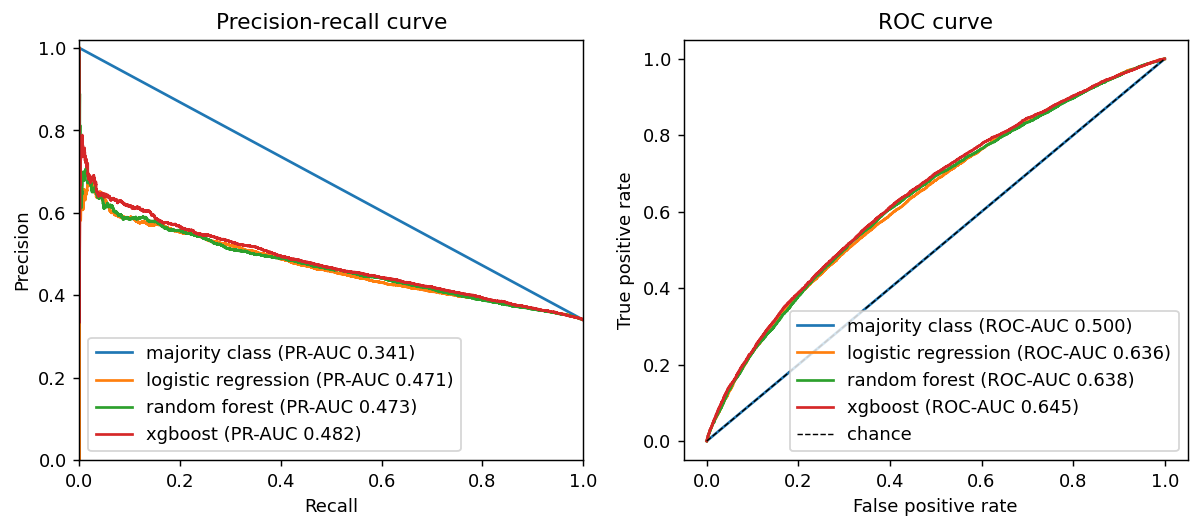

**Chosen model: xgboost** - highest validation PR-AUC among the trained models (logistic regression 0.471, random forest 0.473, xgboost 0.482); threshold tuned for F1 on validation only.

In [7]:
cmp_ = table("model_comparison_val.csv", index_col=0)
display(cmp_[["precision", "recall", "f1", "pr_auc", "roc_auc", "capture_rate_20", "threshold"]])
display(Image(OUT / "val_pr_roc.png"))
display(Markdown(f"**Chosen model: {R['chosen']['model']}** - {R['chosen']['reason']}."))

## Interpretable coefficients (M4-12 stand-in)
Top 15 negative and positive logistic-regression coefficients.

In [8]:
display(Markdown("Full model (structured + title components). The title components are anonymous SVD dimensions, so they are hard to read:"))
display(table("logreg_coefficients.csv", index_col=0))
display(Markdown("Structured features only, in plain words (`python -m src.coef_structured`):"))
display(table("logreg_coefficients_structured.csv", index_col=0)[["coefficient", "in_plain_words"]])

Full model (structured + title components). The title components are anonymous SVD dimensions, so they are hard to read:

,coefficient,direction
title_tfidf_svd_5,-2.0753,negative
title_tfidf_svd_12,-1.2895,negative
title_tfidf_svd_11,-1.1995,negative
title_tfidf_svd_20,-1.1205,negative
title_tfidf_svd_48,-1.0436,negative
title_tfidf_svd_81,-0.8377,negative
title_tfidf_svd_69,-0.8065,negative
title_tfidf_svd_24,-0.7847,negative
title_tfidf_svd_57,-0.7750,negative
title_tfidf_svd_58,-0.6877,negative


Structured features only, in plain words (`python -m src.coef_structured`):

,coefficient,in_plain_words
tag_pandas,0.5963,question tagged pandas: more likely to be reso...
tag_r,0.4376,question tagged r: more likely to be resolved
tag_sql,0.3513,question tagged sql: more likely to be resolved
missing_account_age,0.3098,deleted asker account: more likely to be resolved
lagged_tag_volume,0.2241,higher tag volume in the previous 4 weeks: mor...
tag_powerbi,0.2143,question tagged powerbi: more likely to be res...
question_word_does,0.1703,title starts with 'does': more likely to be re...
question_word_what,0.1502,title starts with 'what': more likely to be re...
n_code_blocks,0.1476,higher number of code blocks: more likely to b...
question_word_should,0.1468,title starts with 'should': more likely to be ...
